In [7]:
from pathlib import Path

# CHANGE THIS to your actual path
DATA_DIR = Path("../data/NCT-CRC-HE-100K")

for class_dir in sorted(DATA_DIR.iterdir()):
    if class_dir.is_dir():
        n = len(list(class_dir.glob("*.tif")))
        print(class_dir.name, n)

ADI 10407
BACK 10566
DEB 11512
LYM 11557
MUC 8896
MUS 13536
NORM 8763
STR 10446
TUM 14317


Total images: 100000
Classes: ['ADI', 'BACK', 'DEB', 'LYM', 'MUC', 'MUS', 'NORM', 'STR', 'TUM']
Batch shape: torch.Size([16, 3, 96, 96])


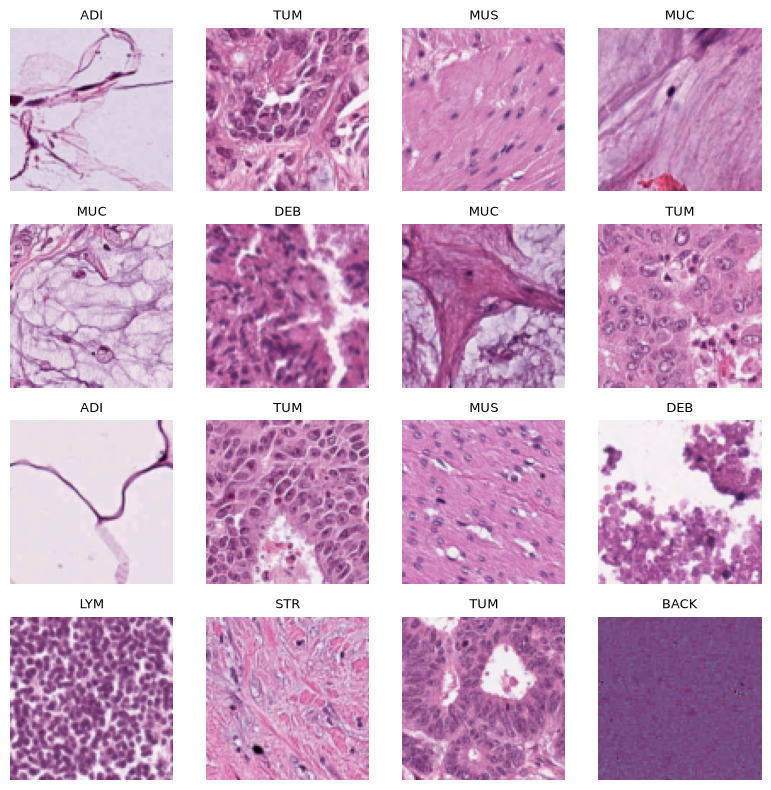

In [9]:
import torch
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

root = "../data/NCT-CRC-HE-100K"   # change this to your path

# 1. Transform: resize and convert the image to a tensor
tfm = transforms.Compose([
    transforms.Resize((96, 96)),
    transforms.ToTensor(),
])

# 2. Dataset: ImageFolder reads class names from the folder names
dataset = datasets.ImageFolder(root, transform=tfm)
print("Total images:", len(dataset))
print("Classes:", dataset.classes)

# 3. DataLoader: gives us batches of 16 shuffled images
loader = DataLoader(dataset, batch_size=16, shuffle=True)

# 4. Take just one batch
images, labels = next(iter(loader))
print("Batch shape:", images.shape)      # expect [16, 3, 96, 96]

# 5. Plot a 4x4 grid
fig, axes = plt.subplots(4, 4, figsize=(8, 8))
for ax, img, lab in zip(axes.flat, images, labels):
    ax.imshow(img.permute(1, 2, 0))      # [C,H,W] -> [H,W,C] for matplotlib
    ax.set_title(dataset.classes[lab], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.savefig("batch_grid.png", dpi=150)
plt.show()